In [2]:
# Deconstructing Dominance
## Barcelona vs Juventus — UEFA Champions League Final, 2015

In [3]:
pip install statsbombpy


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import warnings
warnings.filterwarnings("ignore")
from statsbombpy import sb

In [5]:
competitions = sb.competitions()
ucl = competitions[competitions["competition_name"] == "Champions League"]
ucl[["season_name", "competition_name"]]

,season_name,competition_name
3,2018/2019,Champions League
4,2017/2018,Champions League
5,2016/2017,Champions League
6,2015/2016,Champions League
7,2014/2015,Champions League
8,2013/2014,Champions League
9,2012/2013,Champions League
10,2011/2012,Champions League
11,2010/2011,Champions League
12,2009/2010,Champions League


In [6]:
comps = sb.competitions()
comps[(comps["season_name"] == "2014/2015") &(comps["competition_name"] == "Champions League")]

,competition_id,season_id,country_name,competition_name,competition_gender,competition_youth,competition_international,season_name,match_updated,match_updated_360,match_available_360,match_available
7,16,26,Europe,Champions League,male,False,False,2014/2015,2024-02-12T12:49:54.914228,2021-06-13T16:17:31.694,None,2024-02-12T12:49:54.914228


In [7]:
match = sb.matches( competition_id=16,season_id=26)
match[ (match["home_team"] == "Juventus") &(match["away_team"] == "Barcelona")]

,match_id,match_date,kick_off,home_score,away_score,match_status,match_status_360,last_updated,last_updated_360,match_week,...,home_manager_country_name,away_manager_id,away_manager_name,away_manager_nickname,away_manager_dob,away_manager_country_id,away_manager_country_name,data_version,shot_fidelity_version,xy_fidelity_version
0,18242,2015-06-06,20:45:00.000,1,3,available,scheduled,2024-02-12T12:49:54.914228,2021-06-13T16:17:31.694,1,...,Italy,793,Luis Enrique Martínez García,Luis Enrique,1970-05-08,214,Spain,1.0.3,None,None


In [8]:
events = sb.events(match_id=18242)

events.head()

,ball_receipt_outcome,ball_recovery_recovery_failure,carry_end_location,clearance_aerial_won,counterpress,dribble_nutmeg,dribble_outcome,dribble_overrun,duel_outcome,duel_type,...,substitution_outcome,substitution_outcome_id,substitution_replacement,substitution_replacement_id,tactics,team,team_id,timestamp,type,under_pressure
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,"{'formation': 41212, 'lineup': [{'player': {'i...",Juventus,224,00:00:00.000,Starting XI,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,"{'formation': 41221, 'lineup': [{'player': {'i...",Barcelona,217,00:00:00.000,Starting XI,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,Juventus,224,00:00:00.000,Half Start,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,Barcelona,217,00:00:00.000,Half Start,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,Juventus,224,00:00:00.000,Half Start,NaN


In [9]:
print("Shape:", events.shape)
print("\nColumns:")
print(events.columns.tolist())
events["type"].value_counts()

Shape: (3433, 80)

Columns:
['ball_receipt_outcome', 'ball_recovery_recovery_failure', 'carry_end_location', 'clearance_aerial_won', 'counterpress', 'dribble_nutmeg', 'dribble_outcome', 'dribble_overrun', 'duel_outcome', 'duel_type', 'duration', 'foul_committed_advantage', 'foul_committed_card', 'foul_committed_offensive', 'foul_committed_type', 'foul_won_advantage', 'foul_won_defensive', 'goalkeeper_body_part', 'goalkeeper_end_location', 'goalkeeper_outcome', 'goalkeeper_position', 'goalkeeper_technique', 'goalkeeper_type', 'id', 'index', 'injury_stoppage_in_chain', 'interception_outcome', 'location', 'match_id', 'minute', 'off_camera', 'pass_aerial_won', 'pass_angle', 'pass_assisted_shot_id', 'pass_backheel', 'pass_body_part', 'pass_cross', 'pass_end_location', 'pass_goal_assist', 'pass_height', 'pass_length', 'pass_miscommunication', 'pass_outcome', 'pass_recipient', 'pass_recipient_id', 'pass_shot_assist', 'pass_switch', 'pass_technique', 'pass_through_ball', 'pass_type', 'period',

type
Pass                 977
Ball Receipt*        868
Carry                825
Pressure             266
Ball Recovery         98
Duel                  55
Foul Committed        40
Foul Won              38
Goal Keeper           36
Miscontrol            36
Dribble               34
Shot                  32
Block                 26
Clearance             25
Dispossessed          24
Dribbled Past         18
Substitution           6
Injury Stoppage        6
Half Start             4
Half End               4
Interception           4
Starting XI            2
Player Off             2
Player On              2
Referee Ball-Drop      2
Tactical Shift         2
Error                  1
Name: count, dtype: int64

In [10]:
shots = events[events["type"] == "Shot"].copy()

print("Total shots:", len(shots))
print("\nShots by team:")
print(shots["team"].value_counts())

print("\nShot outcomes:")
print(shots["shot_outcome"].value_counts())

print("\nTotal xG by team:")
print(shots.groupby("team")["shot_statsbomb_xg"].sum())

passes = events[events["type"] == "Pass"].copy()

print("Total passes:", len(passes))
print("\nPasses by team:")
print(passes["team"].value_counts())

print("\nPasses leading to shots:")
print(events["pass_shot_assist"].sum())

print("\nPasses leading directly to goals:")
print(events["pass_goal_assist"].sum())

print("Players:", events["player"].nunique())
print("Events with locations:", events["location"].notna().sum())
print("Events with pass end locations:", events["pass_end_location"].notna().sum())
print("Shots with freeze-frame data:", shots["shot_freeze_frame"].notna().sum())

Total shots: 32

Shots by team:
team
Barcelona    17
Juventus     15
Name: count, dtype: int64

Shot outcomes:
shot_outcome
Off T      14
Saved      10
Goal        4
Wayward     3
Blocked     1
Name: count, dtype: int64

Total xG by team:
team
Barcelona    2.270658
Juventus     1.384188
Name: shot_statsbomb_xg, dtype: float64
Total passes: 977

Passes by team:
team
Barcelona    600
Juventus     377
Name: count, dtype: int64

Passes leading to shots:
20

Passes leading directly to goals:
2
Players: 28
Events with locations: 3405
Events with pass end locations: 977
Shots with freeze-frame data: 32


In [11]:
pip install mplsoccer

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
shots=events[events["type"]=="Shot"].copy()
print(shots[["team", "player", "location","shot_outcome", "shot_statsbomb_xg"]].head())

           team                         player       location shot_outcome  \
3020   Juventus           Carlos Alberto Tevez  [100.0, 40.0]        Off T   
3021   Juventus                   Patrice Evra  [108.0, 43.0]      Wayward   
3022  Barcelona                   Ivan Rakitić  [112.0, 38.0]         Goal   
3023   Juventus      Arturo Erasmo Vidal Pardo  [101.0, 52.0]        Off T   
3024  Barcelona  Neymar da Silva Santos Junior  [102.0, 47.0]        Off T   

      shot_statsbomb_xg  
3020           0.046274  
3021           0.060870  
3022           0.378384  
3023           0.051605  
3024           0.055677  


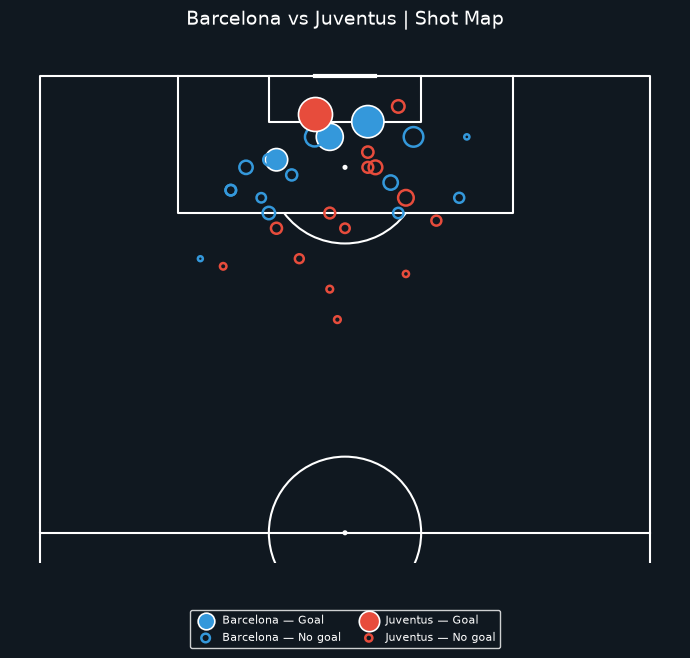

In [13]:
import matplotlib.pyplot as plt
from mplsoccer import VerticalPitch

pitch = VerticalPitch(
    pitch_type="statsbomb",
    half=True,
    pitch_color="#101820",
    line_color="white",
    linewidth=1.5
)

fig, ax = pitch.draw(figsize=(7, 10))
fig.set_facecolor("#101820")

teams = {
    "Barcelona": "#3498db",
    "Juventus": "#e74c3c"
}

for team, color in teams.items():
    team_shots = shots[shots["team"] == team]

    # Goals: filled circles
    goals = team_shots[team_shots["shot_outcome"] == "Goal"]

    pitch.scatter(
        goals["location"].apply(lambda loc: loc[0]),
        goals["location"].apply(lambda loc: loc[1]),
        ax=ax,
        s=goals["shot_statsbomb_xg"] * 1000,
        color=color,
        edgecolors="white",
        linewidth=1.2,
        label=f"{team} — Goal",
        zorder=3
    )

    # Non-goals: hollow circles
    non_goals = team_shots[team_shots["shot_outcome"] != "Goal"]

    pitch.scatter(
        non_goals["location"].apply(lambda loc: loc[0]),
        non_goals["location"].apply(lambda loc: loc[1]),
        ax=ax,
        s=non_goals["shot_statsbomb_xg"] * 1000,
        facecolors="none",
        edgecolors=color,
        linewidth=1.8,
        label=f"{team} — No goal",
        zorder=3
    )

ax.set_title(
    "Barcelona vs Juventus | Shot Map",
    color="white",
    fontsize=14,
    pad=15
)

legend = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.08),
    ncol=2,
    columnspacing=1.5,
    handletextpad=0.5,
    markerscale=0.6,
    facecolor="#101820",
    edgecolor="white",
    labelcolor="white",
    fontsize=8
)

plt.subplots_adjust(bottom=0.12)
plt.show()

In [14]:
passes = events[(events["type"] == "Pass") &(events["team"] == "Barcelona") &(events["pass_outcome"].isna())].copy()
print("Completed passes:", len(passes))
print(passes[["player", "pass_recipient"]].head())


Completed passes: 515
                      player            pass_recipient
13     Gerard Piqué Bernabéu     Daniel Alves da Silva
14     Daniel Alves da Silva  Sergio Busquets i Burgos
15  Sergio Busquets i Burgos     Daniel Alves da Silva
16     Daniel Alves da Silva              Ivan Rakitić
17     Daniel Alves da Silva     Gerard Piqué Bernabéu


In [15]:
#Average positins of players while passing
import numpy as np
import pandas as pd
passes[["x", "y"]] = passes["location"].apply(lambda loc: pd.Series(loc))
player_positions = passes.groupby("player").agg( avg_x=("x", "mean"),avg_y=("y", "mean"), passes_made=("player", "count")).reset_index()
player_positions

,player,avg_x,avg_y,passes_made
0,Andrés Iniesta Luján,73.840000,22.380000,50
1,Daniel Alves da Silva,66.181818,70.961039,77
2,Gerard Piqué Bernabéu,37.857143,53.228571,35
3,Ivan Rakitić,69.533333,56.155556,45
4,Javier Alejandro Mascherano,45.750000,30.400000,40
5,Jordi Alba Ramos,63.317460,13.920635,63
6,Lionel Andrés Messi Cuccittini,78.550000,51.700000,60
7,Luis Alberto Suárez Díaz,71.285714,43.190476,21
8,Marc-André ter Stegen,9.571429,42.523810,21
9,Neymar da Silva Santos Junior,86.540541,22.324324,37


In [18]:
# Count completed passes between each passer and receiver
pass_counts = events[
    (events["type"] == "Pass") &
    (events["team"] == "Barcelona") &
    (events["pass_outcome"].isna()) &
    (events["pass_recipient"].notna())
].groupby(
    ["player", "pass_recipient"]
).size().reset_index(name="pass_count")

pass_counts.head()

,player,pass_recipient,pass_count
0,Andrés Iniesta Luján,Daniel Alves da Silva,3
1,Andrés Iniesta Luján,Gerard Piqué Bernabéu,1
2,Andrés Iniesta Luján,Ivan Rakitić,2
3,Andrés Iniesta Luján,Javier Alejandro Mascherano,4
4,Andrés Iniesta Luján,Jordi Alba Ramos,14


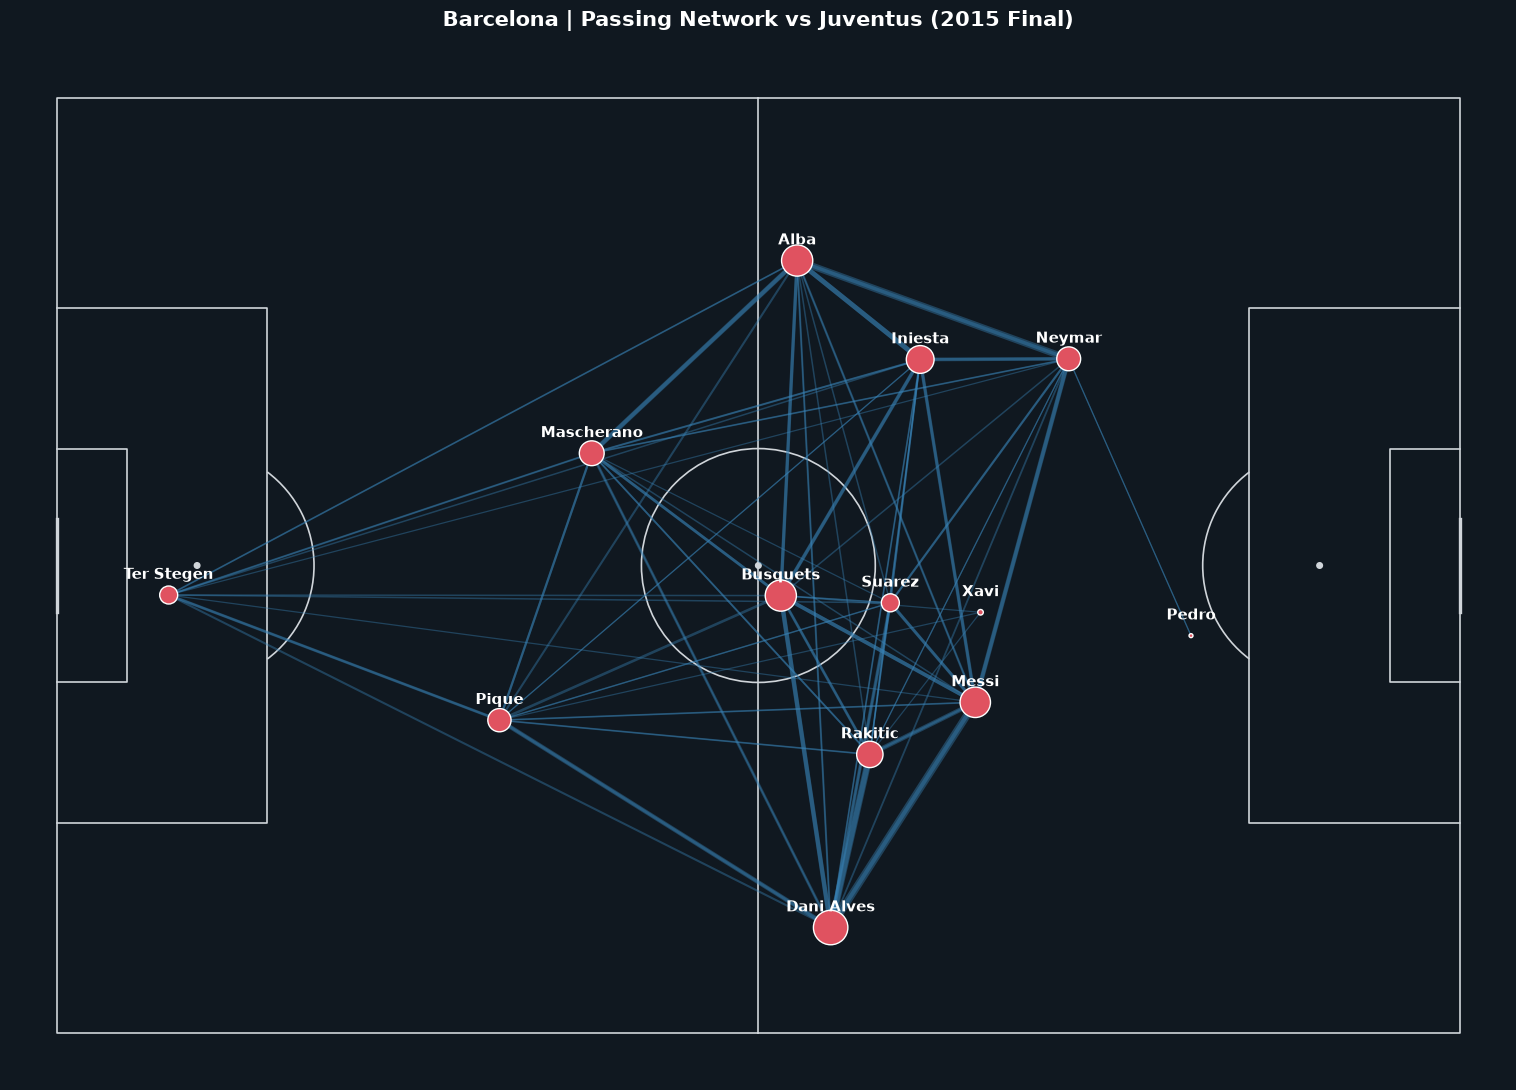

In [19]:
from mplsoccer import Pitch
import matplotlib.pyplot as plt

pitch = Pitch(
    pitch_type="statsbomb",
    pitch_color="#101820",
    line_color="#D0D5DA",
    linewidth=1.2
)

fig, ax = pitch.draw(figsize=(16, 11))
fig.set_facecolor("#101820")

# Passing connections
for _, row in pass_counts.iterrows():
    passer = player_positions[
        player_positions["player"] == row["player"]
    ]
    receiver = player_positions[
        player_positions["player"] == row["pass_recipient"]
    ]

    if not passer.empty and not receiver.empty:
        x1, y1 = passer[["avg_x", "avg_y"]].iloc[0]
        x2, y2 = receiver[["avg_x", "avg_y"]].iloc[0]

        pitch.lines(
            x1, y1, x2, y2,
            ax=ax,
            color="#3984B8",
            lw=0.7 + row["pass_count"] * 0.2,
            alpha=0.4,
            zorder=1
        )

# Player nodes
pitch.scatter(
    player_positions["avg_x"],
    player_positions["avg_y"],
    s=player_positions["passes_made"] * 8,
    color="#E05260",
    edgecolors="white",
    linewidth=1,
    ax=ax,
    zorder=3
)

short_names = {
    "Marc-André ter Stegen": "Ter Stegen",
    "Gerard Piqué Bernabéu": "Pique",
    "Jordi Alba Ramos": "Alba",
    "Ivan Rakitić": "Rakitic",
    "Andrés Iniesta Luján": "Iniesta",
    "Xavier Hernández Creus": "Xavi",
    "Lionel Andrés Messi Cuccittini": "Messi",
    "Sergio Busquets i Burgos": "Busquets",
    "Luis Alberto Suárez Díaz": "Suarez",
    "Neymar da Silva Santos Junior": "Neymar",
    "Pedro Eliezer Rodríguez Ledesma": "Pedro",
    "Javier Alejandro Mascherano": "Mascherano",
    "Daniel Alves da Silva": "Dani Alves"
}

for _, player in player_positions.iterrows():
    name = short_names.get(player["player"])

    if name is None:
        continue

    pitch.annotate(
        name,
        (player["avg_x"], player["avg_y"]),
        ax=ax,
        color="white",
        fontsize=11,
        fontweight="bold",
        ha="center",
        va="bottom",
        xytext=(0, 9),
        textcoords="offset points",
        zorder=4,
        path_effects=[]
    )

ax.set_title(
    "Barcelona | Passing Network vs Juventus (2015 Final)",
    color="white",
    fontsize=15,
    fontweight="bold",
    pad=18
)

plt.show()

In [ ]:
passes = events[(events["type"] == "Pass") &(events["team"] == "Juventus") &(events["pass_outcome"].isna())].copy()
print("Completed passes:", len(passes))
print(passes[["player", "pass_recipient"]].head())


Completed passes: 295
                       player             pass_recipient
6        Carlos Alberto Tevez  Arturo Erasmo Vidal Pardo
7   Arturo Erasmo Vidal Pardo               Andrea Pirlo
8                Andrea Pirlo            Andrea Barzagli
9             Andrea Barzagli           Leonardo Bonucci
10           Leonardo Bonucci                 Paul Pogba


In [ ]:
#Average positins of players while passing
import numpy as np
import pandas as pd
passes[["x", "y"]] = passes["location"].apply(lambda loc: pd.Series(loc))
player_positions = passes.groupby("player").agg( avg_x=("x", "mean"),avg_y=("y", "mean"), passes_made=("player", "count")).reset_index()
player_positions

,player,avg_x,avg_y,passes_made
0,Andrea Barzagli,42.533333,48.866667,30
1,Andrea Pirlo,53.850000,36.800000,40
2,Arturo Erasmo Vidal Pardo,65.838710,54.064516,31
3,Carlos Alberto Tevez,71.791667,31.000000,24
4,Claudio Marchisio,59.785714,50.357143,28
5,Fernando Llorente Torres,93.000000,33.000000,3
6,Gianluigi Buffon,9.047619,41.238095,21
7,Leonardo Bonucci,38.483871,26.612903,31
8,Patrice Evra,72.136364,8.954545,22
9,Paul Pogba,71.153846,25.192308,26


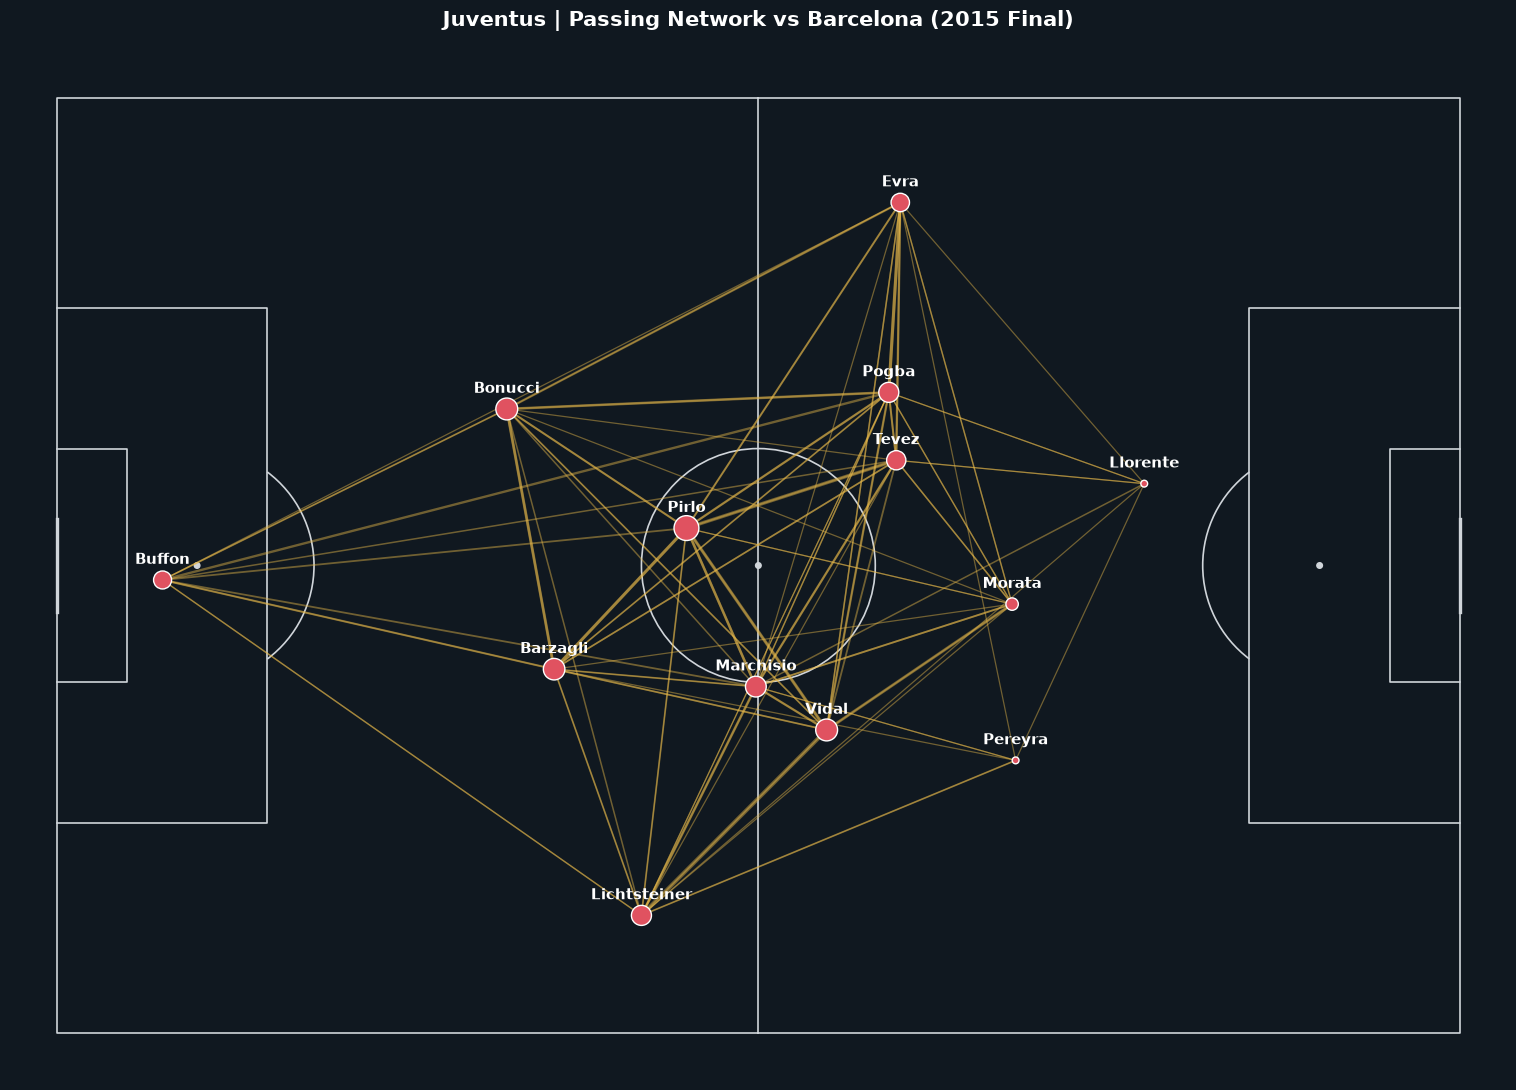

In [ ]:
import matplotlib.pyplot as plt
from mplsoccer import Pitch

# Count passes between each pair of Juventus players
juve_pass_counts = (
    passes.groupby(["player", "pass_recipient"])
    .size()
    .reset_index(name="pass_count")
)

pitch = Pitch(
    pitch_type="statsbomb",
    pitch_color="#101820",
    line_color="#D0D5DA",
    linewidth=1.2
)

fig, ax = pitch.draw(figsize=(16, 11))
fig.set_facecolor("#101820")

# Passing connections
for _, row in juve_pass_counts.iterrows():
    passer = player_positions[
        player_positions["player"] == row["player"]
    ]
    receiver = player_positions[
        player_positions["player"] == row["pass_recipient"]
    ]

    if not passer.empty and not receiver.empty:
        x1, y1 = passer[["avg_x", "avg_y"]].iloc[0]
        x2, y2 = receiver[["avg_x", "avg_y"]].iloc[0]

        pitch.lines(
            x1, y1, x2, y2,
            ax=ax,
            color="#E6B84A",
            lw=0.7 + row["pass_count"] * 0.2,
            alpha=0.45,
            zorder=1
        )

# Player nodes
pitch.scatter(
    player_positions["avg_x"],
    player_positions["avg_y"],
    s=player_positions["passes_made"] * 8,
    color="#E05260",
    edgecolors="white",
    linewidth=1,
    ax=ax,
    zorder=3
)

# Short names for readability
juve_names = {
    "Andrea Barzagli": "Barzagli",
    "Andrea Pirlo": "Pirlo",
    "Arturo Erasmo Vidal Pardo": "Vidal",
    "Carlos Alberto Tevez": "Tevez",
    "Claudio Marchisio": "Marchisio",
    "Fernando Llorente Torres": "Llorente",
    "Gianluigi Buffon": "Buffon",
    "Leonardo Bonucci": "Bonucci",
    "Patrice Evra": "Evra",
    "Paul Pogba": "Pogba",
    "Roberto Maximiliano Pereyra": "Pereyra",
    "Stephan Lichtsteiner": "Lichtsteiner",
    "Álvaro Borja Morata Martín": "Morata"
}

for _, player in player_positions.iterrows():
    name = juve_names.get(player["player"], player["player"])

    pitch.annotate(
        name,
        (player["avg_x"], player["avg_y"]),
        ax=ax,
        color="white",
        fontsize=11,
        fontweight="bold",
        ha="center",
        va="bottom",
        xytext=(0, 9),
        textcoords="offset points",
        zorder=4
    )

ax.set_title(
    "Juventus | Passing Network vs Barcelona (2015 Final)",
    color="white",
    fontsize=15,
    fontweight="bold",
    pad=18
)

plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

teams = ["Barcelona", "Juventus"]

completed_passes = [
    len(events[
        (events["type"] == "Pass") &
        (events["team"] == team) &
        (events["pass_outcome"].isna())
    ])
    for team in teams
]

total_shots = [
    len(shots[shots["team"] == team])
    for team in teams
]

total_xg = [
    shots.loc[
        shots["team"] == team,
        "shot_statsbomb_xg"
    ].sum()
    for team in teams
]

comparison = pd.DataFrame({
    "Team": teams,
    "Completed Passes": completed_passes,
    "Shots": total_shots,
    "xG": total_xg
})

comparison

,Team,Completed Passes,Shots,xG
0,Barcelona,515,17,2.270658
1,Juventus,295,15,1.384188


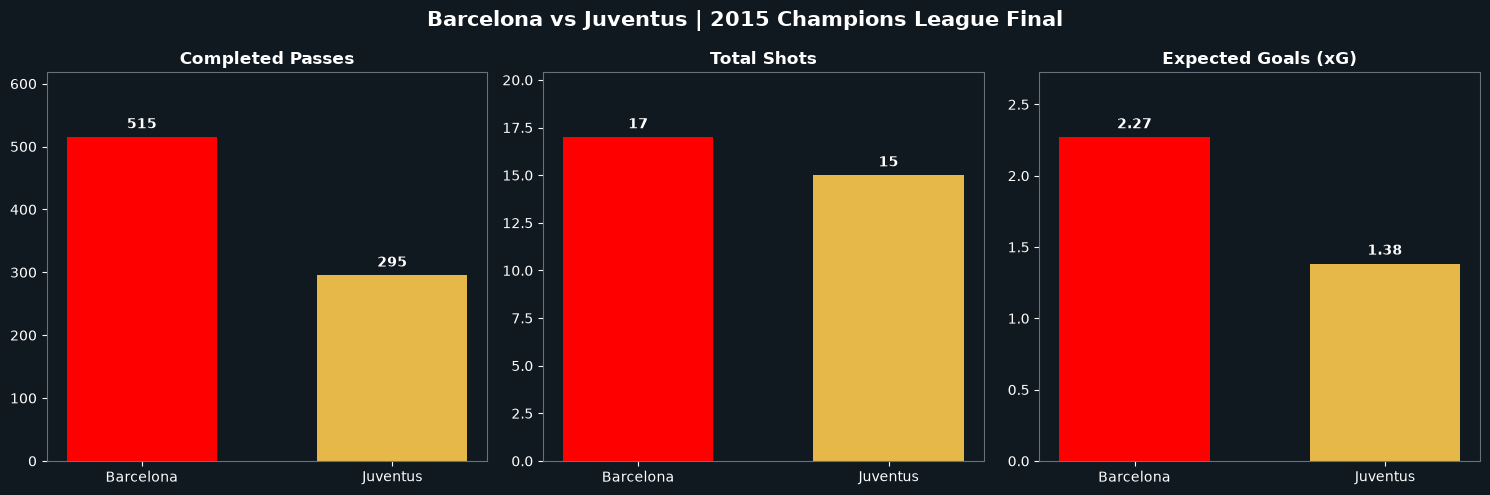

In [ ]:
import matplotlib.pyplot as plt

teams = comparison["Team"]
colors = ["#FF0000", "#E6B84A"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor("#101820")

metrics = [
    ("Completed Passes", "Completed Passes"),
    ("Shots", "Total Shots"),
    ("xG", "Expected Goals (xG)")
]

for ax, (column, title) in zip(axes, metrics):
    bars = ax.bar(
        teams,
        comparison[column],
        color=colors,
        width=0.6
    )

    ax.set_title(title, color="white", fontweight="bold")
    ax.set_facecolor("#101820")
    ax.tick_params(colors="white")
    ax.set_ylim(0, comparison[column].max() * 1.2)
    ax.bar_label(bars, fmt="%.2f" if column == "xG" else "%.0f",
                 color="white", padding=4, fontweight="bold")

    for spine in ax.spines.values():
        spine.set_color("#65717C")

fig.suptitle(
    "Barcelona vs Juventus | 2015 Champions League Final",
    color="white",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
print([
    col for col in events.columns
    if col in [
        "possession", "possession_team", "team",
        "type", "shot_outcome", "pass_outcome"
    ]
])

print(events["shot_outcome"].value_counts(dropna=False))

['pass_outcome', 'possession', 'possession_team', 'shot_outcome', 'team', 'type']
shot_outcome
NaN        3401
Off T        14
Saved        10
Goal          4
Wayward       3
Blocked       1
Name: count, dtype: int64


In [ ]:
# Get all failed passes
failed_passes = events[
    (events["type"] == "Pass") &
    (events["pass_outcome"].notna())
].copy()

# Show failed passes and the team that controlled the possession
failed_passes[
    ["team", "player", "possession", "possession_team", "pass_outcome"]
].head(15)

,team,player,possession,possession_team,pass_outcome
12,Juventus,Leonardo Bonucci,2,Juventus,Incomplete
20,Barcelona,Javier Alejandro Mascherano,4,Barcelona,Incomplete
50,Juventus,Gianluigi Buffon,11,Juventus,Incomplete
52,Barcelona,Sergio Busquets i Burgos,11,Juventus,Incomplete
83,Barcelona,Neymar da Silva Santos Junior,15,Barcelona,Incomplete
99,Juventus,Arturo Erasmo Vidal Pardo,19,Juventus,Incomplete
139,Barcelona,Daniel Alves da Silva,22,Barcelona,Incomplete
142,Juventus,Andrea Barzagli,23,Juventus,Incomplete
147,Barcelona,Lionel Andrés Messi Cuccittini,24,Barcelona,Out
152,Barcelona,Lionel Andrés Messi Cuccittini,26,Barcelona,Out


In [ ]:
# Map each possession number to the team controlling it
possession_teams = (
    events[["possession", "possession_team"]]
    .drop_duplicates("possession")
    .set_index("possession")["possession_team"]
)

# Keep failed passes
failed_passes = events[
    (events["type"] == "Pass") &
    (events["pass_outcome"].notna())
].copy()

# Find the next possession and check whether it belongs to the opponent
failed_passes["next_possession"] = failed_passes["possession"] + 1
failed_passes["next_possession_team"] = (
    failed_passes["next_possession"].map(possession_teams)
)

failed_passes["opponent_possession"] = (
    failed_passes["next_possession_team"] !=
    failed_passes["possession_team"]
)

print(
    failed_passes[
        ["possession_team", "possession", "pass_outcome",
         "next_possession", "next_possession_team",
         "opponent_possession"]
    ].head(15).to_string(index=False)
)

possession_team  possession pass_outcome  next_possession next_possession_team  opponent_possession
       Juventus           2   Incomplete                3            Barcelona                 True
      Barcelona           4   Incomplete                5             Juventus                 True
       Juventus          11   Incomplete               12             Juventus                False
       Juventus          11   Incomplete               12             Juventus                False
      Barcelona          15   Incomplete               16             Juventus                 True
       Juventus          19   Incomplete               20            Barcelona                 True
      Barcelona          22   Incomplete               23             Juventus                 True
       Juventus          23   Incomplete               24            Barcelona                 True
      Barcelona          24          Out               25             Juventus                 True


In [ ]:
# Keep only shots that were goals or saved by the goalkeeper
target_shots = events[
    (events["type"] == "Shot") &
    (events["shot_outcome"].isin(["Goal", "Saved"]))
].copy()

# Summarize goals and shots on target by possession
shot_summary = (
    target_shots
    .groupby(["possession", "possession_team", "shot_outcome"])
    .size()
    .unstack(fill_value=0)
)

# Ensure both outcome columns exist
for outcome in ["Goal", "Saved"]:
    if outcome not in shot_summary.columns:
        shot_summary[outcome] = 0

print(shot_summary[["Goal", "Saved"]].to_string())

shot_outcome                Goal  Saved
possession possession_team             
10         Barcelona           1      0
26         Barcelona           0      1
51         Barcelona           0      1
85         Barcelona           0      1
91         Juventus            0      1
104        Barcelona           0      1
114        Juventus            1      1
135        Juventus            0      1
148        Barcelona           1      1
180        Juventus            0      1
185        Juventus            0      1
194        Barcelona           1      0


In [ ]:
# Convert the shot summary's index into regular columns
shot_summary_reset = shot_summary.reset_index()

# Rename columns to make the join clear
shot_summary_reset = shot_summary_reset.rename(columns={
    "possession": "opponent_possession_id",
    "possession_team": "opponent_team"
})

# Merge failed-pass possessions with the shot summary
results = opponent_possessions.merge(
    shot_summary_reset,
    on=["opponent_possession_id", "opponent_team"],
    how="left"
)

# Replace missing shot counts with zero
results[["Goal", "Saved"]] = results[["Goal", "Saved"]].fillna(0)

print(results.to_string(index=False))

team_that_lost_pass  opponent_possession_id opponent_team  Goal  Saved
           Juventus                       3     Barcelona   0.0    0.0
          Barcelona                       5      Juventus   0.0    0.0
          Barcelona                      16      Juventus   0.0    0.0
           Juventus                      20     Barcelona   0.0    0.0
          Barcelona                      23      Juventus   0.0    0.0
           Juventus                      24     Barcelona   0.0    0.0
          Barcelona                      25      Juventus   0.0    0.0
          Barcelona                      27      Juventus   0.0    0.0
           Juventus                      28     Barcelona   0.0    0.0
           Juventus                      32     Barcelona   0.0    0.0
          Barcelona                      33      Juventus   0.0    0.0
           Juventus                      34     Barcelona   0.0    0.0
           Juventus                      37     Barcelona   0.0    0.0
      

In [ ]:
# Summarize opponent outcomes by the team that lost the pass
team_summary = (
    results.groupby("team_that_lost_pass")
    .agg(
        Opponent_Possessions=("opponent_possession_id", "nunique"),
        Opponent_Goals=("Goal", "sum"),
        Opponent_Saved_Shots=("Saved", "sum")
    )
    .reset_index()
)

print(team_summary.to_string(index=False))

team_that_lost_pass  Opponent_Possessions  Opponent_Goals  Opponent_Saved_Shots
          Barcelona                    36             1.0                   4.0
           Juventus                    37             2.0                   2.0


In [ ]:
failed_pass_counts = (
    failed_passes.groupby("possession_team")
    .size()
    .rename("Failed_Passes")
)

final_summary = team_summary.merge(
    failed_pass_counts,
    left_on="team_that_lost_pass",
    right_index=True
)

final_summary["Goals_per_100_Failed_Passes"] = (
    final_summary["Opponent_Goals"]
    / final_summary["Failed_Passes"] * 100
).round(2)

final_summary["Saved_Shots_per_100_Failed_Passes"] = (
    final_summary["Opponent_Saved_Shots"]
    / final_summary["Failed_Passes"] * 100
).round(2)

print(final_summary.to_string(index=False))

team_that_lost_pass  Opponent_Possessions  Opponent_Goals  Opponent_Saved_Shots  Failed_Passes  Goals_per_100_Failed_Passes  Saved_Shots_per_100_Failed_Passes
          Barcelona                    36             1.0                   4.0             84                         1.19                               4.76
           Juventus                    37             2.0                   2.0             83                         2.41                               2.41


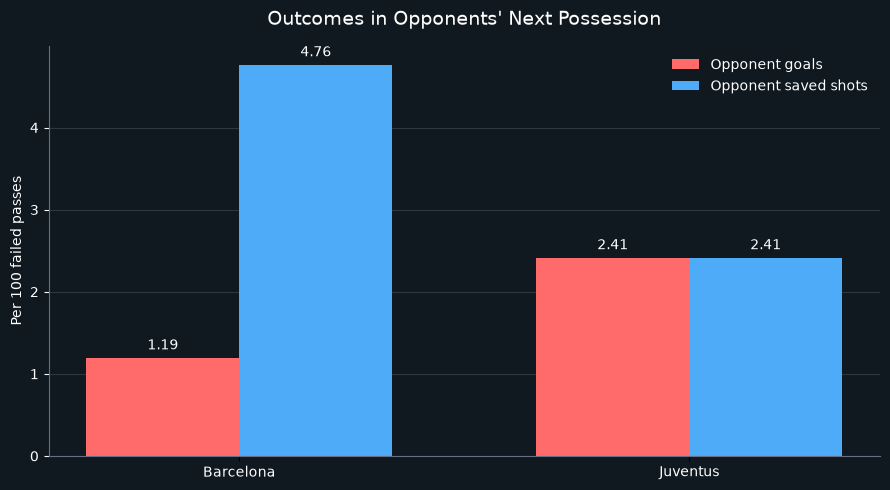

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

teams = ["Barcelona", "Juventus"]
goals = final_summary["Goals_per_100_Failed_Passes"].values
saved_shots = final_summary["Saved_Shots_per_100_Failed_Passes"].values

x = np.arange(len(teams))
width = 0.34

fig, ax = plt.subplots(figsize=(9, 5))
fig.patch.set_facecolor("#101820")
ax.set_facecolor("#101820")

bars1 = ax.bar(
    x - width / 2, goals, width,
    label="Opponent goals",
    color="#ff6b6b"
)

bars2 = ax.bar(
    x + width / 2, saved_shots, width,
    label="Opponent saved shots",
    color="#4dabf7"
)

ax.set_title(
    "Outcomes in Opponents' Next Possession",
    color="white", fontsize=14, pad=15
)
ax.set_ylabel("Per 100 failed passes", color="white")
ax.set_xticks(x)
ax.set_xticklabels(teams, color="white")
ax.tick_params(axis="y", colors="white")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#667085")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

for bars in [bars1, bars2]:
    ax.bar_label(
        bars, fmt="%.2f", padding=4,
        color="white", fontsize=10
    )

legend = ax.legend(frameon=False)
for text_item in legend.get_texts():
    text_item.set_color("white")

plt.tight_layout()
plt.show()

In [ ]:
barca_passes = events[
    (events["type"] == "Pass") &
    (events["team"] == "Barcelona")
][[
    "team",
    "player",
    "location",
    "pass_end_location",
    "pass_outcome"
]]

barca_passes.head()

,team,player,location,pass_end_location,pass_outcome
13,Barcelona,Gerard Piqué Bernabéu,"[30.0, 66.0]","[39.0, 71.0]",NaN
14,Barcelona,Daniel Alves da Silva,"[39.0, 71.0]","[40.0, 64.0]",NaN
15,Barcelona,Sergio Busquets i Burgos,"[40.0, 64.0]","[43.0, 73.0]",NaN
16,Barcelona,Daniel Alves da Silva,"[44.0, 73.0]","[49.0, 74.0]",NaN
17,Barcelona,Daniel Alves da Silva,"[43.0, 76.0]","[16.0, 66.0]",NaN


In [ ]:
import numpy as np
barca_passes=events[(events["type"]=="Pass")&(events["team"]=="Barcelona")&(events["pass_outcome"].isna())&(events["location"].notna())&(events["pass_end_location"].notna())]
barca_passes[["location","pass_end_location"]].head()

,location,pass_end_location
13,"[30.0, 66.0]","[39.0, 71.0]"
14,"[39.0, 71.0]","[40.0, 64.0]"
15,"[40.0, 64.0]","[43.0, 73.0]"
16,"[44.0, 73.0]","[49.0, 74.0]"
17,"[43.0, 76.0]","[16.0, 66.0]"


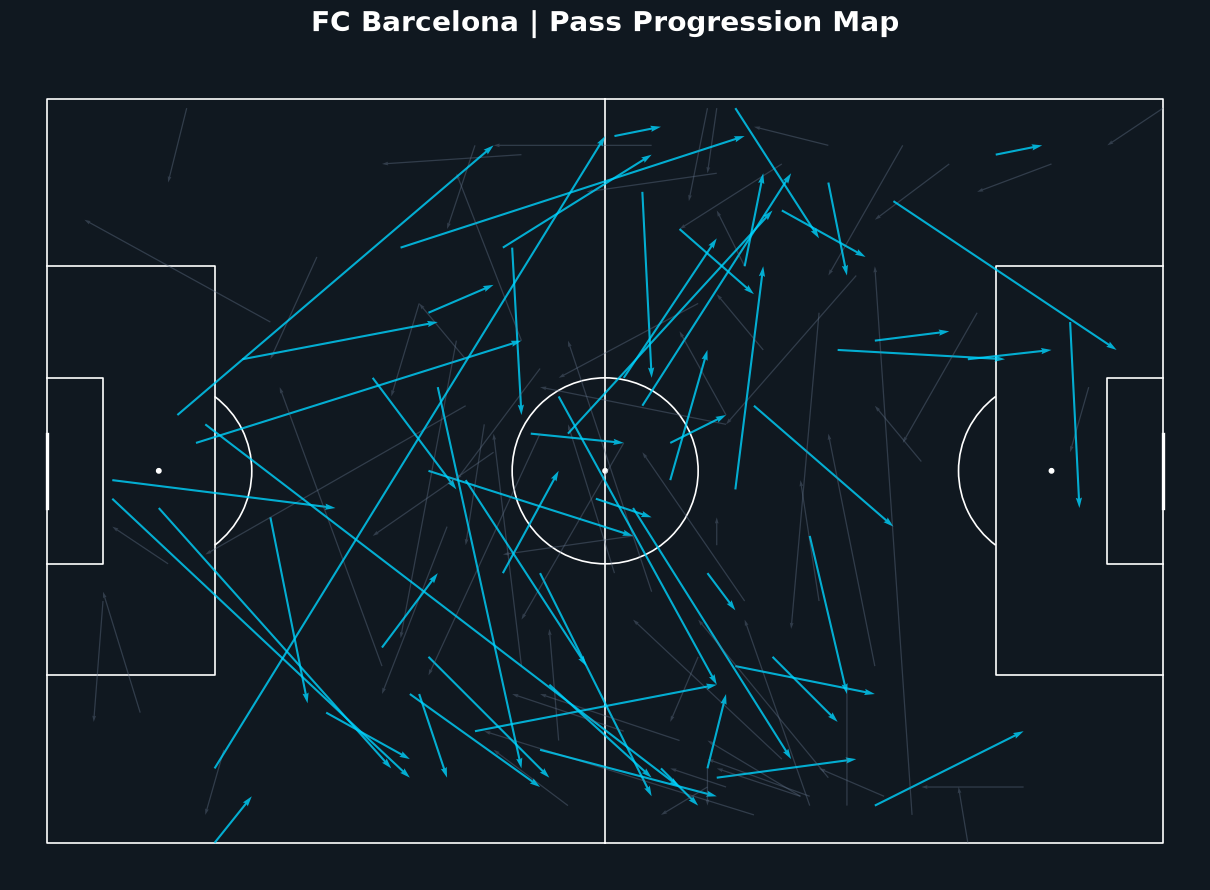

In [ ]:
import matplotlib.pyplot as plt
from mplsoccer import Pitch

# Keep only 25% of passes for a cleaner map
sampled_passes = barca_passes.sample(
    frac=0.25,
    random_state=42
)

pitch = Pitch(
    pitch_type="statsbomb",
    pitch_color="#101820",
    line_color="#FFFFFF",
    linewidth=1.2
)

fig, ax = pitch.draw(figsize=(14, 9))
fig.set_facecolor("#101820")

for _, row in sampled_passes.iterrows():
    x, y = row["location"]
    end_x, end_y = row["pass_end_location"]

    # Cyan = forward pass; grey = sideways/backward pass
    if end_x > x:
        color = "#00D4FF"
        alpha = 0.8
        width = 1.5
    else:
        color = "#64748B"
        alpha = 0.4
        width = 0.9

    pitch.arrows(
        x, y, end_x, end_y,
        color=color,
        alpha=alpha,
        width=width,
        headwidth=3,
        ax=ax
    )

ax.set_title(
    "FC Barcelona | Pass Progression Map",
    color="white",
    fontsize=20,
    pad=22,
    fontweight="bold"
)

plt.show()

In [23]:
import pandas as pd

# Keep Barcelona's ball recoveries with valid locations
barca_recoveries = events[
    (events["type"] == "Ball Recovery") &
    (events["team"] == "Barcelona") &
    (events["location"].notna())
].copy()

# Extract x and y coordinates
coords = pd.DataFrame(
    barca_recoveries["location"].tolist(),
    index=barca_recoveries.index,
    columns=["x", "y"]
)

barca_recoveries[["x", "y"]] = coords

# Keep recoveries in the final third
barca_final_third_recoveries = barca_recoveries[
    barca_recoveries["x"] >= 80
].copy()

print("Barcelona recoveries in final third:",
      len(barca_final_third_recoveries))

barca_final_third_recoveries[
    ["player", "x", "y"]
].head()

Barcelona recoveries in final third: 17


,player,x,y
3154,Luis Alberto Suárez Díaz,103.0,27.0
3155,Jordi Alba Ramos,82.0,10.0
3157,Neymar da Silva Santos Junior,91.0,10.0
3162,Neymar da Silva Santos Junior,90.0,28.0
3172,Neymar da Silva Santos Junior,107.0,23.0


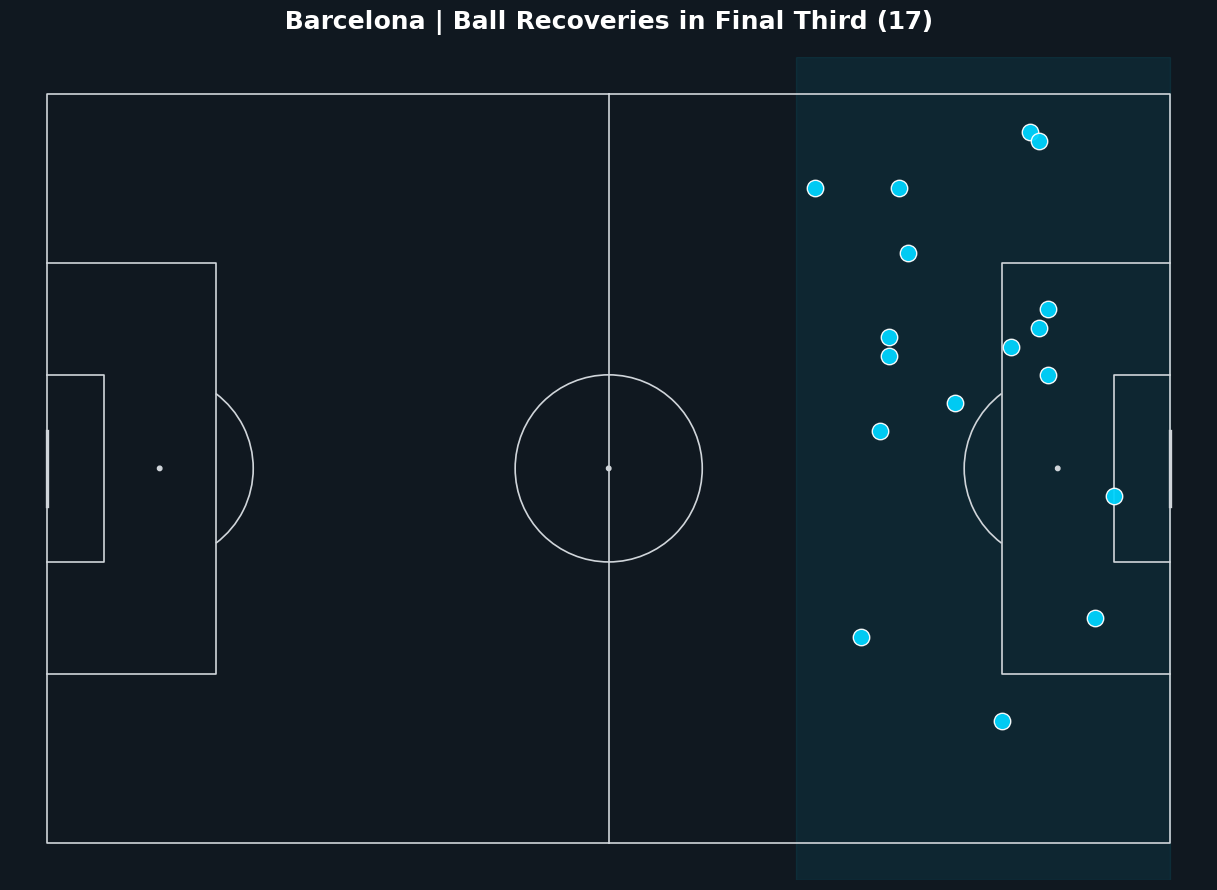

In [24]:
import matplotlib.pyplot as plt
from mplsoccer import Pitch
import pandas as pd

coords = pd.DataFrame(
    barca_final_third_recoveries["location"].tolist(),
    index=barca_final_third_recoveries.index,
    columns=["x", "y"]
)

barca_final_third_recoveries[["x", "y"]] = coords

pitch = Pitch(
    pitch_type="statsbomb",
    pitch_color="#101820",
    line_color="#D0D5DA",
    linewidth=1.2
)

fig, ax = pitch.draw(figsize=(14, 9))
fig.set_facecolor("#101820")

# Highlight the opponent's final third
ax.axvspan(80, 120, color="#00D4FF", alpha=0.08, zorder=0)

pitch.scatter(
    barca_final_third_recoveries["x"],
    barca_final_third_recoveries["y"],
    ax=ax,
    color="#00D4FF",
    edgecolors="white",
    linewidth=1,
    s=140,
    alpha=0.95,
    zorder=3
)

ax.set_title(
    f"Barcelona | Ball Recoveries in Final Third ({len(barca_final_third_recoveries)})",
    color="white",
    fontsize=18,
    fontweight="bold",
    pad=20
)

plt.show()

In [25]:
# Possessions containing Barcelona's final-third recoveries
recovery_possessions = set(
    barca_final_third_recoveries["possession"].dropna()
)

# Barcelona shots on target in those possessions
shots_on_target = events[
    (events["type"] == "Shot") &
    (events["team"] == "Barcelona") &
    (events["possession"].isin(recovery_possessions)) &
    (events["shot_outcome"].isin(["Goal", "Saved"]))
]

print("Final-third recoveries:",
      len(barca_final_third_recoveries))

print("Shots on target in those possessions:",
      len(shots_on_target))

shots_on_target[
    ["player", "minute", "second", "shot_outcome", "possession"]
]

Final-third recoveries: 17
Shots on target in those possessions: 4


,player,minute,second,shot_outcome,possession
3028,Neymar da Silva Santos Junior,26,42,Saved,51
3030,Luis Alberto Suárez Díaz,39,30,Saved,85
3041,Lionel Andrés Messi Cuccittini,67,51,Saved,148
3042,Luis Alberto Suárez Díaz,67,53,Goal,148


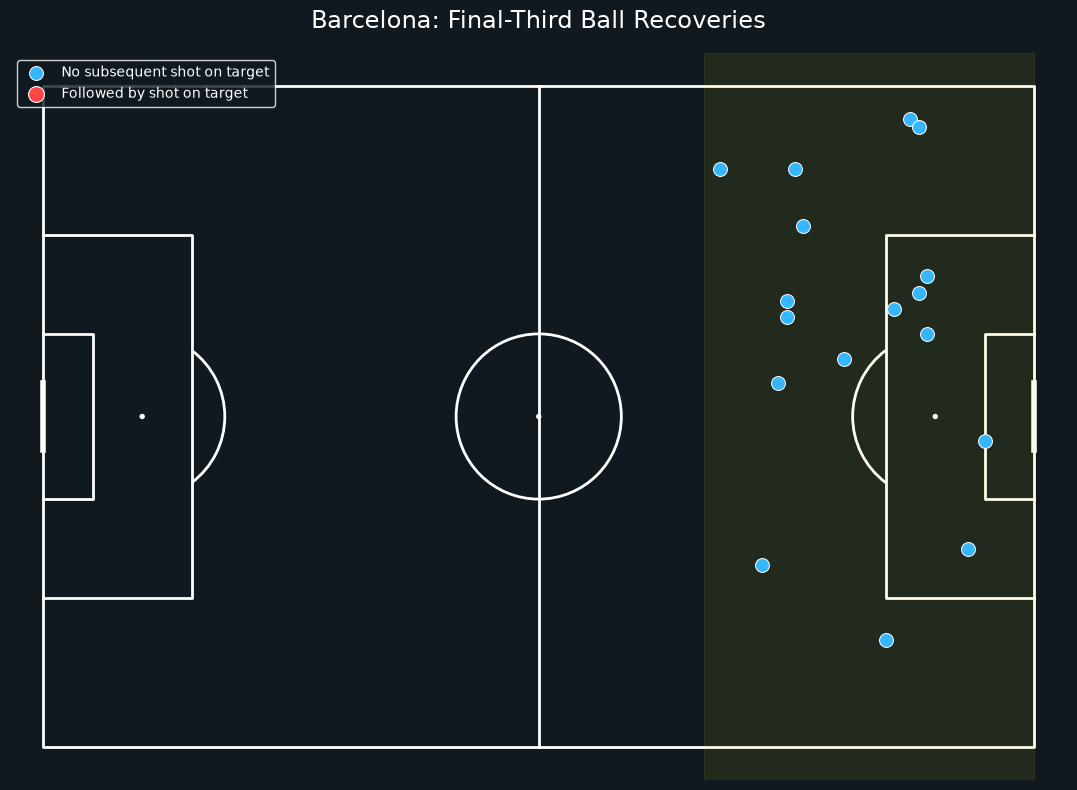

Total final-third recoveries: 17
Recoveries followed by a shot on target: 0
Other recoveries: 17


In [26]:
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import Pitch

# Get the event order in the original events DataFrame
events_ordered = events.reset_index(drop=True).copy()
events_ordered["event_order"] = events_ordered.index

# Final-third recoveries, with their event order
recoveries = events_ordered[
    (events_ordered["type"] == "Ball Recovery") &
    (events_ordered["team"] == "Barcelona") &
    (events_ordered["location"].notna())
].copy()

recoveries[["x", "y"]] = pd.DataFrame(
    recoveries["location"].tolist(),
    index=recoveries.index
)

recoveries = recoveries[recoveries["x"] >= 80].copy()

# Barcelona shots on target
shots = events_ordered[
    (events_ordered["type"] == "Shot") &
    (events_ordered["team"] == "Barcelona") &
    (events_ordered["shot_outcome"].isin(["Goal", "Saved"])) &
    (events_ordered["location"].notna())
].copy()

# Mark a recovery if a shot on target occurs later in that possession
shot_recovery_possessions = set()

for _, recovery in recoveries.iterrows():
    later_shots = shots[
        (shots["possession"] == recovery["possession"]) &
        (shots["event_order"] > recovery["event_order"])
    ]

    if not later_shots.empty:
        shot_recovery_possessions.add(recovery.name)

recoveries["led_to_shot_on_target"] = (
    recoveries.index.isin(shot_recovery_possessions)
)

# Plot
pitch = Pitch(
    pitch_type="statsbomb",
    pitch_color="#101820",
    line_color="white"
)

fig, ax = pitch.draw(figsize=(13, 8))
fig.set_facecolor("#101820")

# Highlight the final third
ax.axvspan(80, 120, color="yellow", alpha=0.08)

# Recoveries NOT followed by a shot on target
no_shot = recoveries[~recoveries["led_to_shot_on_target"]]
pitch.scatter(
    no_shot["x"], no_shot["y"],
    ax=ax, s=100, color="#35B6FF",
    edgecolors="white", linewidth=0.7,
    label="No subsequent shot on target", zorder=3
)

# Recoveries followed by a shot on target
with_shot = recoveries[recoveries["led_to_shot_on_target"]]
pitch.scatter(
    with_shot["x"], with_shot["y"],
    ax=ax, s=130, color="#FF4545",
    edgecolors="white", linewidth=0.8,
    label="Followed by shot on target", zorder=4
)

ax.set_title(
    "Barcelona: Final-Third Ball Recoveries",
    color="white", fontsize=17, pad=18
)

legend = ax.legend(
    loc="upper left",
    facecolor="#101820",
    edgecolor="white",
    labelcolor="white"
)

plt.show()

print("Total final-third recoveries:", len(recoveries))
print("Recoveries followed by a shot on target:", len(with_shot))
print("Other recoveries:", len(no_shot))

In [38]:
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import Pitch

iniesta = events[
    (events["player"] == "Andrés Iniesta Luján") &
    (events["location"].notna())
].copy()

iniesta[["x", "y"]] = pd.DataFrame(
    iniesta["location"].tolist(),
    index=iniesta.index,
    columns=["x", "y"]
)

print("Iniesta events with locations:", len(iniesta))

Iniesta events with locations: 179


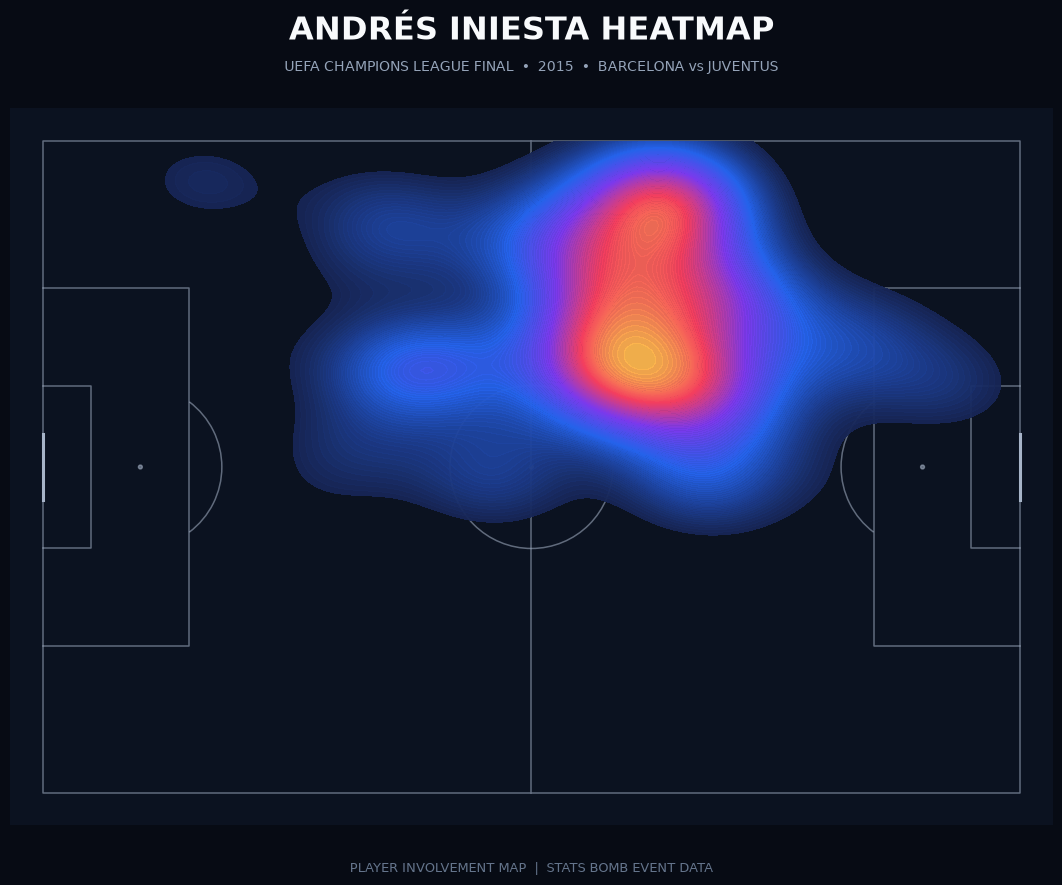

In [41]:
import matplotlib.pyplot as plt
from mplsoccer import Pitch
from matplotlib.colors import LinearSegmentedColormap

# Custom premium heatmap gradient
colors = [
    "#172554",  # Deep navy
    "#2563EB",  # Blue
    "#7C3AED",  # Violet
    "#F43F5E",  # Pink-red
    "#FDBA4D"   # Warm gold
]

iniesta_cmap = LinearSegmentedColormap.from_list(
    "iniesta_heat",
    colors,
    N=256
)

# Dark football pitch
pitch = Pitch(
    pitch_type="statsbomb",
    pitch_color="#0B1220",
    line_color="#A7B4C8",
    linewidth=1.1,
    line_alpha=0.55
)

fig, ax = pitch.draw(figsize=(14, 9))
fig.set_facecolor("#070B14")

# Heatmap layer
pitch.kdeplot(
    iniesta["x"],
    iniesta["y"],
    ax=ax,
    fill=True,
    levels=100,
    thresh=0.06,
    cmap=iniesta_cmap,
    alpha=0.95
)

# Title and subtitle
fig.text(
    0.5, 0.96,
    "ANDRÉS INIESTA HEATMAP",
    ha="center",
    color="#F8FAFC",
    fontsize=23,
    fontweight="bold"
)

fig.text(
    0.5, 0.925,
    "UEFA CHAMPIONS LEAGUE FINAL  •  2015  •  BARCELONA vs JUVENTUS",
    ha="center",
    color="#94A3B8",
    fontsize=10
)

fig.text(
    0.5, 0.035,
    "PLAYER INVOLVEMENT MAP  |  STATS BOMB EVENT DATA",
    ha="center",
    color="#64748B",
    fontsize=9
)

plt.tight_layout(rect=[0.02, 0.07, 0.98, 0.90])
plt.show()

In [43]:
defensive_types = ["Duel", "Interception", "Block", "Clearance"]

barca_defensive = events[
    (events["team"] == "Barcelona") &
    (events["type"].isin(defensive_types)) &
    (events["location"].notna())
].copy()

barca_defensive["type"].value_counts()

type
Duel            27
Clearance       17
Block            7
Interception     2
Name: count, dtype: int64

In [44]:
barca_defensive[
    barca_defensive["type"] == "Duel"
]["duel_type"].value_counts(dropna=False)

duel_type
Tackle         19
Aerial Lost     8
Name: count, dtype: int64

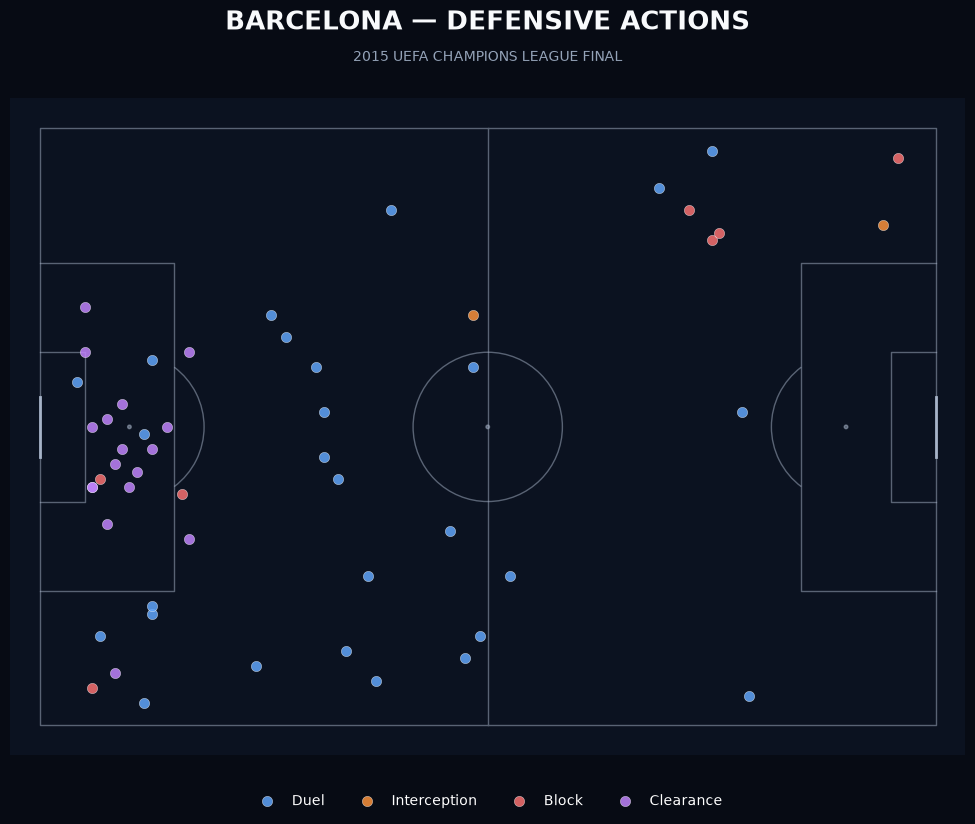

In [45]:
import matplotlib.pyplot as plt
from mplsoccer import Pitch

coords = pd.DataFrame(
    barca_defensive["location"].tolist(),
    index=barca_defensive.index,
    columns=["x", "y"]
)

barca_defensive[["x", "y"]] = coords

pitch = Pitch(
    pitch_type="statsbomb",
    pitch_color="#0B1220",
    line_color="#A7B4C8",
    linewidth=1,
    line_alpha=0.5
)

fig, ax = pitch.draw(figsize=(14, 9))
fig.set_facecolor("#070B14")

colors = {
    "Duel": "#60A5FA",
    "Interception": "#FB923C",
    "Block": "#F87171",
    "Clearance": "#C084FC"
}

for action, color in colors.items():
    subset = barca_defensive[barca_defensive["type"] == action]

    if not subset.empty:
        pitch.scatter(
            subset["x"], subset["y"],
            ax=ax,
            s=55,
            color=color,
            alpha=0.85,
            edgecolors="white",
            linewidth=0.3,
            label=action
        )

fig.text(
    0.5, 0.96,
    "BARCELONA — DEFENSIVE ACTIONS",
    ha="center", color="#F8FAFC",
    fontsize=19, fontweight="bold"
)

fig.text(
    0.5, 0.925,
    "2015 UEFA CHAMPIONS LEAGUE FINAL",
    ha="center", color="#94A3B8", fontsize=10
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.04),
    ncol=4,
    frameon=False,
    labelcolor="white"
)

plt.tight_layout(rect=[0.02, 0.07, 0.98, 0.90])
plt.show()

In [47]:
juve_defensive = events[
    (events["team"] == "Juventus") &
    (events["type"].isin(defensive_types)) &
    (events["location"].notna())
].copy()
juve_defensive["type"].value_counts()

type
Duel            28
Block           19
Clearance        8
Interception     2
Name: count, dtype: int64

In [48]:
coords = pd.DataFrame(
    juve_defensive["location"].tolist(),
    index=juve_defensive.index,
    columns=["x", "y"]
)

juve_defensive[["x", "y"]] = coords

juve_defensive[["type", "x", "y"]].head()

,type,x,y
3125,Clearance,4.0,37.0
3131,Clearance,10.0,41.0
3132,Clearance,17.0,29.0
3133,Clearance,16.0,33.0
3136,Clearance,5.0,49.0


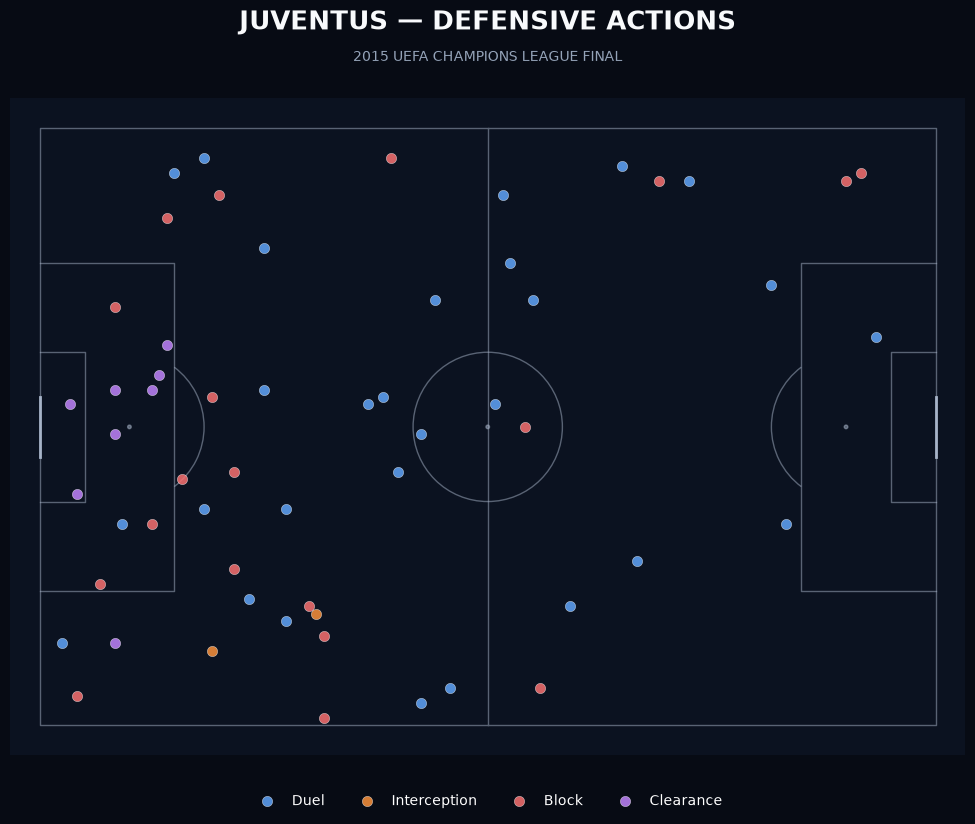

In [49]:
fig, ax = pitch.draw(figsize=(14, 9))
fig.set_facecolor("#070B14")

colors = {
    "Duel": "#60A5FA",
    "Interception": "#FB923C",
    "Block": "#F87171",
    "Clearance": "#C084FC"
}

for action, color in colors.items():
    subset = juve_defensive[juve_defensive["type"] == action]

    pitch.scatter(
        subset["x"],
        subset["y"],
        ax=ax,
        s=55,
        color=color,
        alpha=0.85,
        edgecolors="white",
        linewidth=0.3,
        label=action
    )

fig.text(
    0.5, 0.96,
    "JUVENTUS — DEFENSIVE ACTIONS",
    ha="center",
    color="#F8FAFC",
    fontsize=19,
    fontweight="bold"
)

fig.text(
    0.5, 0.925,
    "2015 UEFA CHAMPIONS LEAGUE FINAL",
    ha="center",
    color="#94A3B8",
    fontsize=10
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.04),
    ncol=4,
    frameon=False,
    labelcolor="white"
)

plt.tight_layout(rect=[0.02, 0.07, 0.98, 0.90])
plt.show()

In [50]:
juve_passes = events[
    (events["type"] == "Pass") &
    (events["team"] == "Juventus") &
    (events["pass_outcome"].isna()) &
    (events["location"].notna()) &
    (events["pass_end_location"].notna())
][[
    "team",
    "player",
    "location",
    "pass_end_location",
    "pass_outcome"
]].copy()

juve_passes.head()

,team,player,location,pass_end_location,pass_outcome
6,Juventus,Carlos Alberto Tevez,"[60.0, 40.0]","[59.0, 42.0]",NaN
7,Juventus,Arturo Erasmo Vidal Pardo,"[58.0, 42.0]","[48.0, 40.0]",NaN
8,Juventus,Andrea Pirlo,"[37.0, 37.0]","[31.0, 39.0]",NaN
9,Juventus,Andrea Barzagli,"[31.0, 39.0]","[31.0, 21.0]",NaN
10,Juventus,Leonardo Bonucci,"[33.0, 19.0]","[48.0, 20.0]",NaN


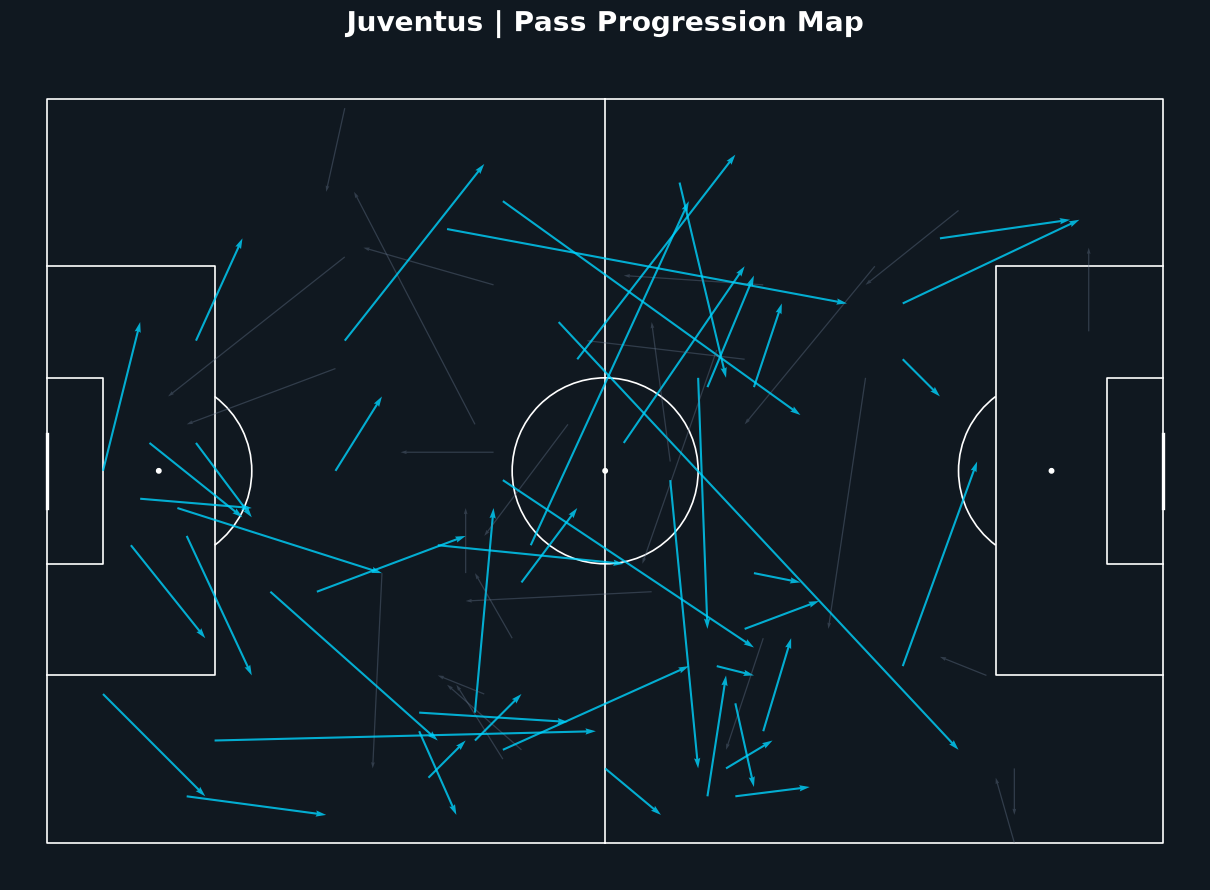

In [51]:
import numpy as np
import matplotlib.pyplot as plt
from mplsoccer import Pitch

# Keep 25% of passes for a cleaner map
sampled_passes = juve_passes.sample(
    frac=0.25,
    random_state=42
)

pitch = Pitch(
    pitch_type="statsbomb",
    pitch_color="#101820",
    line_color="#FFFFFF",
    linewidth=1.2
)

fig, ax = pitch.draw(figsize=(14, 9))
fig.set_facecolor("#101820")

for _, row in sampled_passes.iterrows():
    x, y = row["location"]
    end_x, end_y = row["pass_end_location"]

    # Cyan = forward pass; grey = sideways/backward pass
    if end_x > x:
        color = "#00D4FF"
        alpha = 0.8
        width = 1.5
    else:
        color = "#64748B"
        alpha = 0.4
        width = 0.9

    pitch.arrows(
        x, y, end_x, end_y,
        color=color,
        alpha=alpha,
        width=width,
        headwidth=3,
        ax=ax
    )

ax.set_title(
    "Juventus | Pass Progression Map",
    color="white",
    fontsize=20,
    pad=22,
    fontweight="bold"
)

plt.show()